# Explainable Credit Risk Scoring

A credit scoring model that predicts the probability that a person will face serious payment problems (default) within 2 years, and that can **explain** its decision.

**Data:** Give Me Some Credit (`cs-training.csv`): 150,000 customers, 10 features. **Target:** `SeriousDlqin2yrs` (1 = default, 0 = no default, about 6.7%, imbalanced). A *classification* problem.

**What this project shows:**
- A data quality audit (finding, proving and fixing the DebtRatio problem)
- Feature selection with IV (classic credit scoring), cross-checked with SHAP
- Imbalanced data (class_weight / scale_pos_weight)
- Credit metrics: KS, Gini, PR-AUC
- Baseline → stronger model (Logistic → XGBoost)
- **Plain-language rejection reasons with SHAP + an LLM** (written in Turkish for Turkish applicants)
- Experiment tracking with MLflow

**Flow:** 1) Load → 2) Data quality & cleaning → 3) IV → 4) Train/test → 5) Logistic → 6) Metrics → 7) Threshold → 8) XGBoost → 9) SHAP → 10) LLM → 11) MLflow

## 1. Load and inspect the data

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("cs-training.csv", index_col=0)
print("Shape:", df.shape)
print(df["SeriousDlqin2yrs"].value_counts(normalize=True))   # about 6.7% default
print()
print(df.isnull().sum())   # MonthlyIncome (about 20%) and NumberOfDependents are missing

Shape: (150000, 11)
SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64

SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64


**Finding:** The target is imbalanced (about 6.7% defaults), so accuracy would be misleading; we use KS, PR-AUC and recall. Two columns have missing values.

## 2. Data Quality Audit & Cleaning

### 2a. Why is DebtRatio broken?
`DebtRatio` should be a debt-to-income ratio (around 0–1), but `describe()` shows a maximum of **329,664**, which is impossible. Instead of clipping it blindly, we investigate why: is income missing for people with a very high DebtRatio?

In [2]:
print(df["DebtRatio"].describe())

high = df[df["DebtRatio"] > df["DebtRatio"].quantile(0.95)]
print(f"\nShare of MISSING income among the top 5% DebtRatio: "
      f"{high['MonthlyIncome'].isnull().mean():.1%}")

count    150000.000000
mean        353.005076
std        2037.818523
min           0.000000
25%           0.175074
50%           0.366508
75%           0.868254
max      329664.000000
Name: DebtRatio, dtype: float64

Share of MISSING income among the top 5% DebtRatio: 94.9%


**Finding:** **94.9%** of the people in the top 5% of DebtRatio have **missing income**. So in rows without income, DebtRatio is no longer a ratio but a meaningless number. The problem is not random: it is systematically linked to missing income.

### 2b. Imputation
We fill empty cells with the **median**.

The median is robust to outliers (the mean would be distorted by extreme incomes).

In [3]:
X = df.drop("SeriousDlqin2yrs", axis=1)
y = df["SeriousDlqin2yrs"]

X["MonthlyIncome"] = X["MonthlyIncome"].fillna(X["MonthlyIncome"].median())
X["NumberOfDependents"] = X["NumberOfDependents"].fillna(X["NumberOfDependents"].median())
print("Missing values left:", X.isnull().sum().sum())

Missing values left: 0


### 2c. Outlier capping: two columns, two methods
- **DebtRatio:** the statistical `quantile(0.99)` did not work (it gives 4,979, because most of the tail is corrupt). **Domain logic:** a debt-to-income ratio should not exceed about 2, so we cap it at 2.
- **RevolvingUtilization:** here the 99th percentile is reasonable (about 1.09), so we use it.

Each problem gets the fix that suits it; we do not apply the same method blindly.

In [4]:
X["DebtRatio"] = X["DebtRatio"].clip(upper=2)

rev = "RevolvingUtilizationOfUnsecuredLines"
X[rev] = X[rev].clip(upper=X[rev].quantile(0.99))

print("DebtRatio new max:", round(X["DebtRatio"].max(), 2))
print("RevolvingUtilization new max:", round(X[rev].max(), 2))

DebtRatio new max: 2.0
RevolvingUtilization new max: 1.09


**Note:** We will see the effect of this cleaning in Section 6: the baseline model's KS goes from **0.46 to 0.51**. The data audit brings a measurable benefit.

## 3. Feature Selection with IV (classic credit scoring)

**IV (Information Value):** a single number that measures how well a feature predicts default; the classic method banks have used for decades.

| IV | Meaning |
|----|-------|
| < 0.02 | useless |
| 0.02–0.1 | weak |
| 0.1–0.3 | medium |
| 0.3–0.5 | strong |
| > 0.5 | suspicious (check for leakage) |

Calculation: split the feature into bins → good/bad share in each bin → **WOE** (the bin's risk weight) → IV = the sum of the contributions.

In [5]:
def calculate_iv(data, feature, target, bins=10):
    d = data[[feature, target]].copy()
    if d[feature].nunique() > bins:
        d["bin"] = pd.qcut(d[feature], q=bins, duplicates="drop")
    else:
        d["bin"] = d[feature]
    g = d.groupby("bin", observed=True)[target].agg(["count", "sum"])
    g.columns = ["total", "bad"]
    g["good"] = g["total"] - g["bad"]
    g["bad"]  = g["bad"].replace(0, 0.5)      # avoid log(0)
    g["good"] = g["good"].replace(0, 0.5)
    g["bad_share"]  = g["bad"]  / g["bad"].sum()
    g["good_share"] = g["good"] / g["good"].sum()
    g["woe"] = np.log(g["good_share"] / g["bad_share"])
    g["iv"]  = (g["good_share"] - g["bad_share"]) * g["woe"]
    return g["iv"].sum()

data = pd.concat([X, y], axis=1)
iv_scores = {c: calculate_iv(data, c, "SeriousDlqin2yrs") for c in X.columns}
iv_df = (pd.DataFrame(iv_scores.items(), columns=["feature", "IV"])
           .sort_values("IV", ascending=False))
print(iv_df.to_string(index=False))

selected = iv_df[iv_df["IV"] > 0.1]["feature"].tolist()
print("\nIV > 0.1 (strong):", selected)

                             feature       IV
RevolvingUtilizationOfUnsecuredLines 1.113378
NumberOfTime30-59DaysPastDueNotWorse 0.471831
                                 age 0.259158
                       MonthlyIncome 0.066954
     NumberOfOpenCreditLinesAndLoans 0.066892
                           DebtRatio 0.025345
                  NumberOfDependents 0.024965
        NumberRealEstateLoansOrLines 0.012091
             NumberOfTimes90DaysLate 0.000000
NumberOfTime60-89DaysPastDueNotWorse 0.000000

IV > 0.1 (strong): ['RevolvingUtilizationOfUnsecuredLines', 'NumberOfTime30-59DaysPastDueNotWorse', 'age']


**Finding 1, validation:** IV ranks `RevolvingUtilization` (1.11), `30-59 days past due` (0.47) and `age` (0.26) as the strongest. This **matches** the SHAP chart in Section 9: a classic method (IV) and a modern one (SHAP), independent of each other, point to the same features.

**Finding 2, an interesting disagreement:** `NumberOfTimes90DaysLate` and `60-89 days past due` score **0.000** in IV, but in SHAP they are among the most important factors. Why? These features are extremely zero-inflated (about 98% of people have 0). IV's simple binning cannot measure such data; tree-based XGBoost + SHAP can. When the two methods disagreed, we did not trust one blindly; we found the reason.

**Decision:** We do NOT drop features for XGBoost (a tree model already ignores weak features). We use IV as a validation and keep all features.

## 4. Train / test split
80/20 with `stratify=y` to keep the class balance. It runs **after cleaning**, so both splits are clean.

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (120000, 10) | Test: (30000, 10)


## 5. Baseline: Logistic Regression
Scaling (logistic regression is sensitive to scale; `fit` only on train = no leakage). `class_weight="balanced"` handles the imbalance.

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on train only (no leakage)
X_test_scaled  = scaler.transform(X_test)

model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)
y_proba = model.predict_proba(X_test_scaled)[:, 1]
print("Baseline trained. First 5 probabilities:", y_proba[:5].round(3))

Baseline trained. First 5 probabilities: [0.17  0.314 0.163 0.211 0.214]


## 6. Evaluation: Credit Metrics
AUC · Gini (2×AUC−1) · PR-AUC (baseline = default rate, about 0.067) · KS (0.40+ is good) · Recall.

In [8]:
from sklearn.metrics import roc_auc_score, average_precision_score, recall_score
from scipy.stats import ks_2samp

def credit_metrics(y_true, y_prob, name):
    a = roc_auc_score(y_true, y_prob); k = ks_2samp(y_prob[y_true==1], y_prob[y_true==0]).statistic
    print(f"{name:20s} | AUC {a:.3f} | Gini {2*a-1:.3f} | PR-AUC {average_precision_score(y_true,y_prob):.3f} | KS {k:.3f}")

credit_metrics(y_test, y_proba, "Logistic (baseline)")
print("Recall @0.50:", round(recall_score(y_test, (y_proba>=0.5).astype(int)), 3))

Logistic (baseline)  | AUC 0.834 | Gini 0.668 | PR-AUC 0.335 | KS 0.509
Recall @0.50: 0.745


**Finding, the effect of cleaning:** After cleaning, the baseline reaches AUC **0.834**, Gini **0.668**, KS **0.509** and recall **0.745**. (Before cleaning, KS was 0.457.) So cleaning DebtRatio and RevolvingUtilization raised KS from **0.46 to 0.51**: a measurable benefit of the data audit.

## 7. Threshold Tuning
0.50 is only the default; the threshold is a **business decision**: lower threshold = higher recall, lower precision.

In [9]:
from sklearn.metrics import precision_score, f1_score
print("Threshold | Precision | Recall | F1")
print("-"*40)
for t in [0.20, 0.30, 0.40, 0.50, 0.60]:
    yp = (y_proba >= t).astype(int)
    print(f"{t:.2f} |   {precision_score(y_test,yp):.3f}   | {recall_score(y_test,yp):.3f} | {f1_score(y_test,yp):.3f}")

Threshold | Precision | Recall | F1
----------------------------------------
0.20 |   0.089   | 0.969 | 0.163
0.30 |   0.126   | 0.896 | 0.221
0.40 |   0.156   | 0.819 | 0.262
0.50 |   0.182   | 0.745 | 0.293
0.60 |   0.216   | 0.670 | 0.326


**Interpretation:** At a threshold of 0.20, recall is about 97% (almost no defaulter is missed), but precision is low (many false alarms); at 0.60 it is the opposite. The "right" threshold depends on a cost analysis: if missing a default is expensive, the bank chooses a low threshold.

## 8. XGBoost Comparison
No scaling (tree-based model) → raw data. Imbalance is handled with `scale_pos_weight` (neg/pos ≈ 14).

In [10]:
from xgboost import XGBClassifier

scale = (y_train==0).sum() / (y_train==1).sum()   # about 14:1
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                    scale_pos_weight=scale, random_state=42, eval_metric="logloss")
xgb.fit(X_train, y_train)                     # raw (unscaled) data
y_proba_xgb = xgb.predict_proba(X_test)[:, 1]

credit_metrics(y_test, y_proba,     "Logistic (baseline)")
credit_metrics(y_test, y_proba_xgb, "XGBoost")

Logistic (baseline)  | AUC 0.834 | Gini 0.668 | PR-AUC 0.335 | KS 0.509
XGBoost              | AUC 0.866 | Gini 0.732 | PR-AUC 0.401 | KS 0.577


**Finding:** XGBoost (KS **0.577**) beats the baseline (KS 0.509) because it captures non-linear relationships. But the gap is smaller than before cleaning, because cleaning also made the baseline stronger. **Note:** once data quality is fixed, a simple model closes much of the gap; a more complex model is not always needed. XGBoost is stronger but less transparent, which is why SHAP is *required*.

## 9. SHAP: Explainability
Positive SHAP → INCREASES risk, negative → decreases it. We expect the global ranking to **match IV**.

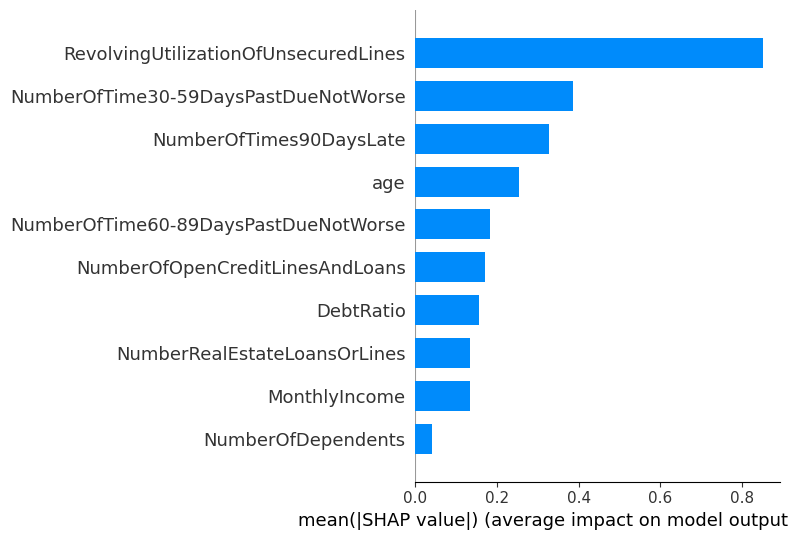

In [11]:
# Colab: !pip install shap
import shap
explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test, plot_type="bar", show=True)

**Finding:** SHAP puts `RevolvingUtilization` at the top, then the delinquency features, then `age`, in line with the IV ranking. The model looks at the signals a credit expert would look at (credit utilisation + payment history). This is evidence that the model has been *checked*.

### Local explanation: one high-risk application (the LLM's input)

In [12]:
risky_idx = int(np.argmax(y_proba_xgb))   # the highest-risk applicant
feature_names = X_test.columns.tolist()
row_vals = X_test.iloc[risky_idx].values
row_shap = shap_values[risky_idx]

contributions = sorted(zip(feature_names, row_vals, row_shap), key=lambda z: abs(z[2]), reverse=True)[:5]
print(f"Default probability: {y_proba_xgb[risky_idx]:.2f}\n")
for name, value, contrib in contributions:
    direction = "INCREASED risk" if contrib > 0 else "decreased risk"
    print(f"{name:38s} | value={value:8.2f} | {direction} (SHAP={contrib:+.3f})")

Default probability: 0.99

NumberOfTimes90DaysLate                | value=    7.00 | INCREASED risk (SHAP=+2.681)
NumberOfTime60-89DaysPastDueNotWorse   | value=    1.00 | INCREASED risk (SHAP=+1.021)
NumberOfTime30-59DaysPastDueNotWorse   | value=    1.00 | INCREASED risk (SHAP=+0.483)
MonthlyIncome                          | value= 2846.00 | INCREASED risk (SHAP=+0.249)
RevolvingUtilizationOfUnsecuredLines   | value=    0.00 | decreased risk (SHAP=-0.166)


**Finding:** The selected customer (probability 0.99) had **7** delinquencies of 90+ days (the largest SHAP contribution), while their credit utilisation of 0 *lowered* the risk. After cleaning, the explanation is based on realistic payment history factors, not on the broken DebtRatio. The model is balanced: some factors raise the risk while others work in the applicant's favour.

## 10. Plain-Language Reason with an LLM
SHAP output is technical. With Groq + Llama-3.3 we turn it into a reason that can be shown to the customer. The reason is written in **Turkish**, because the use case is a Turkish bank's applicants. In Colab: `!pip install groq` and add `GROQ_API_KEY` to Secrets.

In [13]:
!pip install groq

In [16]:
# Colab: !pip install groq
from groq import Groq
from google.colab import userdata

# Turkish names for the features, because the reason is written for Turkish applicants
feature_labels_tr = {
    "RevolvingUtilizationOfUnsecuredLines": "kredi/limit kullanım oranı",
    "age": "yaş",
    "NumberOfTime30-59DaysPastDueNotWorse": "30-59 gün ödeme gecikmesi sayısı",
    "DebtRatio": "borç/gelir oranı",
    "MonthlyIncome": "aylık gelir",
    "NumberOfOpenCreditLinesAndLoans": "açık kredi/hesap sayısı",
    "NumberOfTimes90DaysLate": "90+ gün ödeme gecikmesi sayısı",
    "NumberRealEstateLoansOrLines": "gayrimenkul kredisi sayısı",
    "NumberOfTime60-89DaysPastDueNotWorse": "60-89 gün ödeme gecikmesi sayısı",
    "NumberOfDependents": "bakmakla yükümlü kişi sayısı",
}
lines = [f"- {feature_labels_tr[f]}: değer {v:.2f}" for f, v, c in contributions if c > 0]   # only risk-increasing factors
summary = "\n".join(lines)

# The prompt is in Turkish so the answer is in Turkish. In English it says:
# "A credit risk model found an application high risk. The factors that increased the risk most: ...
#  Based on these factors, write a short (2-3 sentences), polite, clear reason in Turkish for the applicant.
#  Do not use technical terms (model, SHAP, score)."
prompt = f"""Bir kredi risk modeli, bir başvuruyu yüksek riskli buldu.
Kararı en çok etkileyen ve riski artıran faktörler:
{summary}

Bu faktörlere dayanarak başvurana yönelik kısa (2-3 cümle), kibar ve anlaşılır
bir Türkçe gerekçe yaz. Teknik terim (model, SHAP, skor) kullanma."""

client = Groq(api_key=userdata.get("GROQ_API_KEY"))
resp = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[{"role": "user", "content": prompt}],
    temperature=0.3,
)
print(resp.choices[0].message.content)

Başvurunuzda, geçmişte sık sık ve uzun süreli ödeme gecikmeleri yaşamanız ve mevcut aylık gelirinizin kredi geri ödemelerini karşılamakta yetersiz kalabileceği değerlendirilmiştir. Bu nedenle, şu anda kredi talebinizi olumlu sonuçlandıramıyoruz. Anlayışınız için teşekkür ederiz.


**Example output (from this run):**
> *Başvurunuzda, geçmişte sık sık ve uzun süreli ödeme gecikmeleri yaşamanız ve mevcut aylık gelirinizin kredi geri ödemelerini karşılamakta yetersiz kalabileceği değerlendirilmiştir. Bu nedenle, şu anda kredi talebinizi olumlu sonuçlandıramıyoruz. Anlayışınız için teşekkür ederiz.*

*English translation: "In your application, it was assessed that you have had frequent and long payment delays in the past, and that your current monthly income may not be enough to cover the loan repayments. For this reason, we cannot approve your credit request at this time. Thank you for your understanding."*

The reason is based on the customer's actual strongest SHAP factors (90+ day delinquencies + low income); it is polite and contains no technical terms. An LLM writes slightly different words on each run, but it should always name the same factors. ML (score) + SHAP (why) + LLM (readable reason) in one pipeline is what separates this project from a generic Kaggle notebook.

## 11. MLflow: Experiment Tracking
We record each model's parameters and metrics: for reproducibility, comparison, and to answer "which settings produced this model?"

In [17]:
!pip install mlflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 81.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 69.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 50.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 34.4 MB/s  0:00:00
  Attempting uninstall: importlib_metadata
    Found existing installation: importlib_metadata 10.1.0
    Uninstalling importlib_metadata-10.1.0:
      Successfully uninstalled importlib_metadata-10.1.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18/18 [mlflow]


In [18]:
# Colab: !pip install mlflow
import mlflow
mlflow.set_experiment("kredi-risk-skorlama")   # experiment name kept from the original run

for name, prob, params in [
    ("logistic", y_proba,     {"model": "LogisticRegression", "class_weight": "balanced"}),
    ("xgboost",  y_proba_xgb, {"model": "XGBoost", "max_depth": 4, "n_estimators": 300}),
]:
    with mlflow.start_run(run_name=name):          # one run per model
        mlflow.log_params(params)                  # the settings
        a = roc_auc_score(y_test, prob)
        mlflow.log_metrics({"AUC": a, "Gini": 2*a-1,
                            "PR_AUC": average_precision_score(y_test, prob),
                            "KS": ks_2samp(prob[y_test==1], prob[y_test==0]).statistic})
print("Both models were logged to MLflow.")

2026/11/02 12:42:51 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/02 12:42:51 INFO mlflow.store.db.utils: Updating database tables
2026/11/02 12:42:56 INFO mlflow.tracking.fluent: Experiment with name 'kredi-risk-skorlama' does not exist. Creating a new experiment.


Both models were logged to MLflow.


### Read the runs back from MLflow
MLflow is not only a logger: we can query the stored runs and compare them. The chart is saved as `mlflow_runs.png` for the README.

,run,model,AUC,Gini,KS,PR_AUC
0,xgboost,XGBoost,0.866,0.732,0.577,0.401
1,logistic,LogisticRegression,0.834,0.668,0.509,0.335


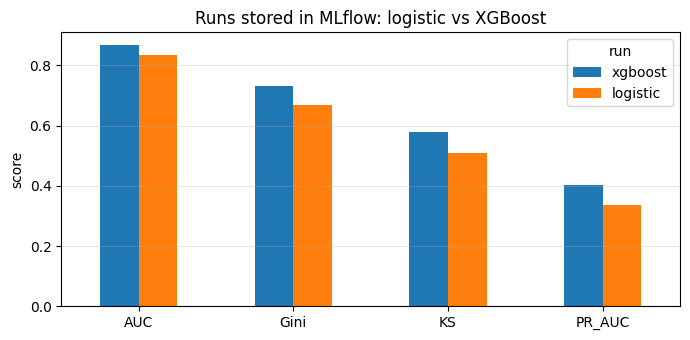

In [19]:
import matplotlib.pyplot as plt

runs = mlflow.search_runs(experiment_names=["kredi-risk-skorlama"])
cols = ["tags.mlflow.runName", "params.model", "metrics.AUC", "metrics.Gini", "metrics.KS", "metrics.PR_AUC"]
table = (runs[cols].rename(columns=lambda c: c.split(".")[-1])
                   .rename(columns={"runName": "run"})
                   .drop_duplicates("run", keep="first")      # keep the latest run per model
                   .round(3))
display(table)

ax = table.set_index("run")[["AUC", "Gini", "KS", "PR_AUC"]].T.plot.bar(figsize=(7, 3.5), rot=0)
ax.set_title("Runs stored in MLflow: logistic vs XGBoost")
ax.set_ylabel("score"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig("mlflow_runs.png", dpi=150); plt.show()

**Finding:** Both models were logged; an `mlflow.db` file was created next to the notebook. With `!mlflow ui` the runs can be compared side by side in the interface.

---
## Summary: Results

| Model | AUC | Gini | KS | PR-AUC |
|-------|-----|------|----|--------|
| Logistic (before cleaning) | 0.802 | 0.604 | 0.457 | 0.323 |
| Logistic (after cleaning) | 0.834 | 0.668 | 0.509 | 0.335 |
| **XGBoost** | **0.866** | **0.732** | **0.577** | **0.401** |

**Key takeaways:**
1. The data quality audit (DebtRatio) raised the baseline KS from 0.46 to 0.51.
2. IV and SHAP agreed on most features; we know why they disagree on the zero-inflated counters.
3. XGBoost is the best model, and SHAP + an LLM make it explainable, which fits regulatory needs.

> *Explainable credit risk scoring: data quality audit, IV feature selection, imbalanced data (class_weight / scale_pos_weight), KS/Gini/PR-AUC evaluation, Logistic → XGBoost comparison, SHAP-based rejection reasons + plain Turkish explanations with an LLM, experiment tracking with MLflow.*

**Possible next steps:** a WOE-based scorecard (classic points card), hyperparameter tuning, custom binning for the count features.